# **Project Name**    - DeepFER: Facial Emotion Recognition Using Deep Learning (EDA)

##### **Project Type**    - EDA (image classification dataset)
##### **Contribution**    - Individual / Team  *(edit as appropriate)*
##### **Team Member 1 -** *(your name)*
##### **Team Member 2 -**
##### **Team Member 3 -**
##### **Team Member 4 -**

# **Project Summary -**

DeepFER aims to recognise seven facial emotions (angry, disgust, fear, happy, neutral, sad and surprise) from face images using convolutional neural networks and transfer learning, with applications in human-computer interaction, mental-health monitoring and customer service. This notebook is the exploratory data analysis (EDA) stage before model building: it finds out what the data looks like, what is wrong with it, and what that means for modelling.

The dataset is a FER-2013-style collection of 48x48 grayscale face crops, organised in train and validation folders with one sub-folder per emotion. The uploaded archive contains 71,774 files, but half of them are an exact duplicate copy stored under images/images, so the real dataset holds 35,887 images (28,821 train, 7,066 validation). The notebook loads only the two real folders. In a single pass it reads every image and computes interpretable image-level features: brightness, contrast, sharpness, edge density, gradient magnitude, left-right asymmetry, upper-lower brightness difference and pixel range. A hash of every image is also stored to detect duplicates.

The integrity checks found no missing labels and no unreadable files, but they did uncover three quality problems: 1,853 redundant copies of identical images; 510 identical images that appear in both train and validation, a leakage that would inflate validation scores; and 57 groups of identical images carrying conflicting emotion labels (160 images). The wrangling step removes the conflicting images, the validation copies of training images, the remaining within-split duplicates and two almost blank frames. Together 1,912 images (5.3%) were removed, leaving 33,975 clean images (27,501 train, 6,474 validation). Duplication was not uniform: about one in three surprise images and 28% of disgust images belonged to duplicate groups, against roughly 4-5% for happy, neutral and sad.

Twenty-two charts follow the univariate, bivariate and multivariate structure. The class distribution is strongly imbalanced: happy (8,793 images, 25.9%) is 19 times larger than disgust (458, 1.3%), so accuracy alone would be misleading and macro-F1, per-class recall and class-weighted training are needed. The train and validation splits are well stratified and statistically indistinguishable in brightness, contrast and edge density, so they can be compared fairly. Among the simple image statistics, brightness differs most between emotions (surprise has a median of about 148 against 121 for sad), yet even this explains only 4.4% of the variance; contrast, edge density, sharpness, asymmetry and vertical brightness explain about 1.6% or less each. Correlation analysis shows that gradient magnitude, sharpness and edge density are largely redundant (r up to 0.80) and that brightness is almost independent of contrast. Pair plots and a PCA projection show heavy class overlap: the first principal component is essentially global brightness (r = 0.99) and the first ten components capture only 66% of pixel variance. Mean-face maps show that most average expressions differ only subtly from neutral (surprise, with a bright face and open mouth, is the exception), and sample grids reveal profile views, glasses, hands covering faces, watermarks, drawings and ambiguous labels.

The main conclusion is that simple global statistics cannot separate emotions, so a convolutional network that learns local features around the eyes, brows and mouth is required. The EDA directly shapes the modelling plan: use the cleaned, de-duplicated data; keep the provided validation split as an untouched test set and carve a stratified validation set out of training; apply class weighting or oversampling for disgust and surprise; use label-preserving augmentation such as horizontal flips, small rotations and mild brightness changes; normalise pixels and replicate the grayscale channel for pretrained backbones; and report macro-F1 with a per-class confusion matrix. The expected value is a trustworthy model whose reported accuracy reflects real generalisation rather than duplicate leakage.

# **GitHub Link -**

*Add your GitHub repository link here, for example: https://github.com/your-username/deepfer-facial-emotion-recognition*

# **Problem Statement**

**Facial expressions are a primary signal of human emotion, but recognising them automatically is hard: expressions differ only subtly, faces vary in pose, lighting, age and occlusion, and real-world datasets contain duplicates, label noise and strong class imbalance. Before a deep learning model can be trusted to classify seven emotions (angry, disgust, fear, happy, neutral, sad, surprise), the dataset must be audited and understood. This EDA examines the quality, balance and visual characteristics of a 48x48 grayscale facial-expression dataset and turns the findings into concrete preprocessing and modelling decisions for DeepFER.**

#### **Define Your Business Objective?**

Build a reliable emotion recognition system (DeepFER) that supports human-computer interaction, mental-health monitoring and customer-service analytics. For the EDA stage the objective is:

1. Verify and improve **data integrity** (duplicates, leakage, conflicting labels, corrupt files) so that reported model accuracy reflects true generalisation.
2. Quantify **class imbalance** and decide how to handle it, so that rare but important emotions (disgust, surprise, fear) are not ignored by the model.
3. Understand **which visual properties differ between emotions** and which are only nuisance variation (lighting, pose), to guide augmentation, normalisation and architecture choices.
4. Produce a **clean, documented dataset** and a modelling plan that the ML notebook can use directly.

# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [1]:
# Import Libraries
import os, glob, zipfile, hashlib, warnings
import numpy as np
import pandas as pd
import cv2                                   # image reading and low-level image statistics
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA
from IPython.display import display

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')

RANDOM_STATE = 42                            # reproducibility
np.random.seed(RANDOM_STATE)

EMOTIONS = ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
PALETTE = dict(zip(EMOTIONS, sns.color_palette('tab10', 7)))   # one fixed colour per emotion

### Dataset Loading

In [2]:
from google.colab import drive
# Mount Google Drive to access your dataset
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Load Dataset
# The zip is extracted once. NOTE: the archive also contains a nested copy 'images/images/' that is
# byte-for-byte identical to train/ + validation/. We deliberately read ONLY train/ and validation/.
ZIP_PATH = '/content/drive/MyDrive/DeepFER: Facial Emotion Recognition Using Deep Learning/Face Emotion Recognition Dataset.zip'  # change if the zip lives elsewhere (e.g. in Google Drive)
DATA_DIR = 'images'

if not os.path.isdir(os.path.join(DATA_DIR, 'train')):
    if not os.path.exists(ZIP_PATH):
        raise FileNotFoundError(f'Upload {ZIP_PATH} next to this notebook (or fix ZIP_PATH).')
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall('.')

for split in ['train', 'validation']:
    found = sorted(os.listdir(os.path.join(DATA_DIR, split)))
    assert found == EMOTIONS, f'Unexpected class folders in {split}: {found}'

nested = os.path.join(DATA_DIR, 'images')
if os.path.isdir(nested):
    n_nested = sum(len(files) for _, _, files in os.walk(nested))
    print(f'Ignoring nested duplicate folder {nested!r} ({n_nested:,} files).')


def extract_features(path):
    # Read one image and return its metadata plus interpretable image-level features.
    img = cv2.imread(path, cv2.IMREAD_UNCHANGED)
    if img is None:
        return None                                              # unreadable / corrupt file
    channels = 1 if img.ndim == 2 else img.shape[2]
    gray = img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gray = gray.astype(np.uint8)
    h, w = gray.shape
    gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0)                       # horizontal gradient
    gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1)                       # vertical gradient
    edges = cv2.Canny(gray, 100, 200)
    left = gray[:, : w // 2].astype(float)
    right = gray[:, w - w // 2:][:, ::-1].astype(float)          # mirrored right half
    return dict(
        height=h, width=w, channels=channels,
        brightness=gray.mean(),                                  # mean grey level
        contrast=gray.std(),                                     # grey-level spread
        min_px=int(gray.min()), max_px=int(gray.max()),          # dynamic range
        sharpness=cv2.Laplacian(gray, cv2.CV_64F).var(),         # variance of Laplacian
        edge_density=(edges > 0).mean(),                         # share of edge pixels
        grad_mag=np.sqrt(gx ** 2 + gy ** 2).mean(),              # mean gradient magnitude
        left_right_asym=np.abs(left - right).mean(),             # left-right asymmetry
        upper_lower=gray[: h // 2].mean() - gray[h // 2:].mean(),# upper minus lower half brightness
        img_hash=hashlib.md5(gray.tobytes()).hexdigest(),        # fingerprint for duplicate detection
    )


records, corrupt_files = [], []
for split in ['train', 'validation']:
    for label in EMOTIONS:
        for path in sorted(glob.glob(os.path.join(DATA_DIR, split, label, '*'))):
            feats = extract_features(path)
            if feats is None:
                corrupt_files.append(path)
                continue
            records.append(dict(path=path, split=split, label=label, **feats))

df = pd.DataFrame(records)
df_raw = df.copy()                                               # untouched copy for the integrity analysis
print(f'Loaded {len(df):,} readable images, {len(corrupt_files)} unreadable files.')

Ignoring nested duplicate folder 'images/images' (35,887 files).
Loaded 35,887 readable images, 0 unreadable files.


### Dataset First View

In [4]:
# Dataset First Look
display(df.head())
display(df.sample(5, random_state=RANDOM_STATE))

,path,split,label,height,width,channels,brightness,contrast,min_px,max_px,sharpness,edge_density,grad_mag,left_right_asym,upper_lower,img_hash
0,images/train/angry/0.jpg,train,angry,48,48,1,117.605903,50.784070,11,209,1742.328532,0.166233,117.901123,44.779514,8.718750,0719d9c55ddd0daeff8bb2e234ae453c
1,images/train/angry/1.jpg,train,angry,48,48,1,126.983507,40.887885,0,219,3142.118297,0.257812,135.712509,34.000000,6.807292,e35949f8325937d7300abf80fb9d6a30
2,images/train/angry/10.jpg,train,angry,48,48,1,111.740885,50.222466,4,254,3482.417823,0.228299,134.767395,45.523438,2.044271,417b0aaf57f5a9b50320e742f32a3b18
3,images/train/angry/10002.jpg,train,angry,48,48,1,121.223090,68.713985,3,231,1949.007592,0.186198,135.472809,30.862847,-8.097222,6a9516e61dcad087383e006aac9dc334
4,images/train/angry/10016.jpg,train,angry,48,48,1,140.697049,57.332374,0,230,3521.216158,0.254774,164.145782,29.161458,40.869792,543cbd51e5e947320bb480c3108891e4


,path,split,label,height,width,channels,brightness,contrast,min_px,max_px,sharpness,edge_density,grad_mag,left_right_asym,upper_lower,img_hash
19098,images/train/neutral/31878.jpg,train,neutral,48,48,1,104.087240,82.560603,0,255,4998.426791,0.218316,172.424484,67.457465,-14.252604,45a9486ed94bd41c647a56ea4e61f971
2043,images/train/angry/26599.jpg,train,angry,48,48,1,87.343316,39.847242,0,255,3806.886285,0.172309,100.203842,41.780382,9.587674,cc1a6eb3bad607ad42d485affb26e7ac
16564,images/train/neutral/15374.jpg,train,neutral,48,48,1,114.471354,37.690973,13,233,1673.092460,0.190104,102.600098,29.937500,7.954861,8b3d56cd36b5f9453d444162834a1ba4
10650,images/train/happy/19380.jpg,train,happy,48,48,1,92.124566,49.764913,18,201,1267.995292,0.208333,104.001541,28.073785,-16.002604,ffcb6a6b79f3bacb90eefc72ab330d88
4955,images/train/fear/14111.jpg,train,fear,48,48,1,145.578993,73.596249,0,255,5278.080919,0.226562,171.958527,57.904514,-37.546875,b311d64fe4b951fb0683c4808f4abc67


### Dataset Rows & Columns count

In [5]:
# Dataset Rows & Columns count
print(f'Rows (images): {df.shape[0]:,}')
print(f'Columns      : {df.shape[1]}')
print()
print(df.groupby('split').size().rename('images'))

Rows (images): 35,887
Columns      : 16

split
train         28821
validation     7066
Name: images, dtype: int64


### Dataset Information

In [6]:
# Dataset Info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35887 entries, 0 to 35886
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   path             35887 non-null  object 
 1   split            35887 non-null  object 
 2   label            35887 non-null  object 
 3   height           35887 non-null  int64  
 4   width            35887 non-null  int64  
 5   channels         35887 non-null  int64  
 6   brightness       35887 non-null  float64
 7   contrast         35887 non-null  float64
 8   min_px           35887 non-null  int64  
 9   max_px           35887 non-null  int64  
 10  sharpness        35887 non-null  float64
 11  edge_density     35887 non-null  float64
 12  grad_mag         35887 non-null  float32
 13  left_right_asym  35887 non-null  float64
 14  upper_lower      35887 non-null  float64
 15  img_hash         35887 non-null  object 
dtypes: float32(1), float64(6), int64(5), object(4)
memory usag

#### Duplicate Values

In [7]:
# Dataset Duplicate Value Count
# Images are compared by the hash of their pixels, so identical pictures are found even if file names differ.
groups = df.groupby('img_hash')
extra_copies = int(df.duplicated('img_hash').sum())
n_dup_groups = int((groups.size() > 1).sum())
cross_split_groups = int((groups['split'].nunique() > 1).sum())
conflict_groups = int((groups['label'].nunique() > 1).sum())
conflict_images = int(df['img_hash'].isin(groups['label'].nunique().loc[lambda s: s > 1].index).sum())

print(f'Redundant copies of identical images : {extra_copies:,}')
print(f'Groups of identical images           : {n_dup_groups:,}')
print(f'  ...appearing in BOTH train and val : {cross_split_groups:,}   (data leakage)')
print(f'  ...with CONFLICTING emotion labels : {conflict_groups:,} groups / {conflict_images:,} images')
print(f'Duplicate file paths                 : {int(df.duplicated("path").sum())}')

Redundant copies of identical images : 1,853
Groups of identical images           : 1,516
  ...appearing in BOTH train and val : 510   (data leakage)
  ...with CONFLICTING emotion labels : 57 groups / 160 images
Duplicate file paths                 : 0


#### Missing Values/Null Values

In [8]:
# Missing Values/Null Values Count
print('Missing cells per column:')
print(df.isnull().sum()[lambda s: s > 0] if df.isnull().sum().sum() else 'None - no missing values in any column.')
print(f'\nUnreadable / corrupt image files: {len(corrupt_files)}')
print(f'Images that are not 48x48       : {int(((df.height != 48) | (df.width != 48)).sum())}')
print(f'Images that are not 1-channel   : {int((df.channels != 1).sum())}')

Missing cells per column:
None - no missing values in any column.

Unreadable / corrupt image files: 0
Images that are not 48x48       : 0
Images that are not 1-channel   : 0


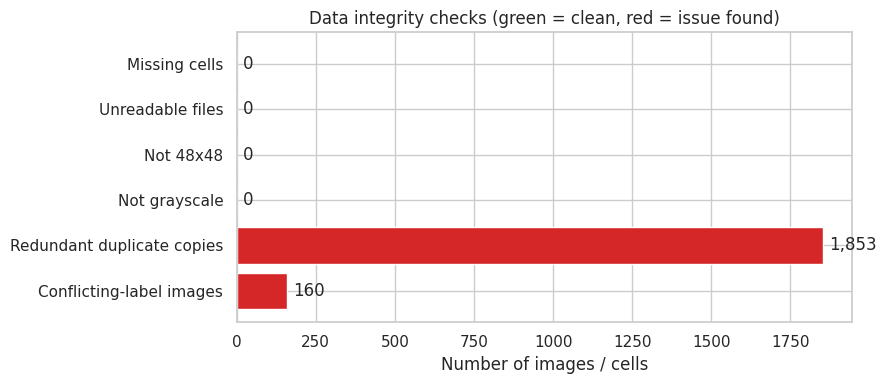

In [9]:
# Visualizing the missing values
# An image dataset has no tabular gaps, so we visualise all integrity checks together instead of a null heat-map.
checks = pd.Series({
    'Missing cells': int(df.isnull().sum().sum()),
    'Unreadable files': len(corrupt_files),
    'Not 48x48': int(((df.height != 48) | (df.width != 48)).sum()),
    'Not grayscale': int((df.channels != 1).sum()),
    'Redundant duplicate copies': extra_copies,
    'Conflicting-label images': conflict_images,
})
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(checks.index, checks.values, color=['#2ca02c' if v == 0 else '#d62728' for v in checks.values])
for b, v in zip(bars, checks.values):
    ax.text(v + 20, b.get_y() + b.get_height() / 2, f'{v:,}', va='center')
ax.invert_yaxis()
ax.set(title='Data integrity checks (green = clean, red = issue found)', xlabel='Number of images / cells')
plt.tight_layout()
plt.show()

### What did you know about your dataset?

* The archive holds **71,774 files, but only 35,887 are unique images**: `images/images/` is an exact duplicate of `train/` + `validation/` and is ignored. The real dataset has **28,821 training and 7,066 validation images** in 7 emotion folders.
* Every image is a **48x48, single-channel grayscale** face crop. There are **no missing values and no unreadable files**.
* The dataset **is not clean**: there are **1,853 redundant copies** of identical images, **510 identical images that appear in both train and validation** (leakage) and **57 groups of identical images with conflicting labels** (160 images).
* The class sizes are very uneven (disgust is by far the smallest), and the pictures include different ages, poses, lighting and some occlusions, so the task is genuinely hard.

## ***2. Understanding Your Variables***

In [10]:
# Dataset Columns
print(list(df.columns))

['path', 'split', 'label', 'height', 'width', 'channels', 'brightness', 'contrast', 'min_px', 'max_px', 'sharpness', 'edge_density', 'grad_mag', 'left_right_asym', 'upper_lower', 'img_hash']


In [11]:
# Dataset Describe
display(df.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
height,35887.0,48.00,0.00,48.00,48.00,48.00,48.00,48.00
width,35887.0,48.00,0.00,48.00,48.00,48.00,48.00,48.00
channels,35887.0,1.00,0.00,1.00,1.00,1.00,1.00,1.00
brightness,35887.0,129.38,33.52,0.00,106.78,129.54,152.64,247.95
contrast,35887.0,54.08,13.65,0.00,44.55,53.67,63.16,113.93
min_px,35887.0,7.73,12.95,0.00,0.00,1.00,11.00,205.00
max_px,35887.0,236.74,24.68,0.00,227.00,247.00,255.00,255.00
sharpness,35887.0,2384.97,1578.20,0.00,1453.01,2110.04,2945.67,31771.74
edge_density,35887.0,0.20,0.04,0.00,0.17,0.20,0.22,0.37
grad_mag,35887.0,122.06,30.61,0.00,101.39,120.45,140.42,373.01


### Variables Description

| Variable | Type | Description |
|---|---|---|
| `path` | text | File path of the image (identifier) |
| `split` | categorical | `train` or `validation` (provided split) |
| `label` | categorical (target) | Emotion class: angry, disgust, fear, happy, neutral, sad, surprise |
| `height`, `width`, `channels` | integer | Image geometry; all images are 48x48 with 1 channel |
| `brightness` | float | Mean grey level (0 = black, 255 = white) |
| `contrast` | float | Standard deviation of grey levels |
| `min_px`, `max_px` | integer | Darkest and brightest pixel: dynamic range used by the image |
| `sharpness` | float | Variance of the Laplacian; higher means more fine detail / sharper edges |
| `edge_density` | float | Fraction of pixels flagged as edges by the Canny detector |
| `grad_mag` | float | Mean Sobel gradient magnitude; overall strength of local intensity change |
| `left_right_asym` | float | Mean absolute difference between the left half and the mirrored right half |
| `upper_lower` | float | Upper-half brightness minus lower-half brightness |
| `img_hash` | text | MD5 hash of the pixels, used only to find duplicates |

### Check Unique Values for each variable.

In [12]:
# Check Unique Values for each variable.
display(df.nunique().rename('unique values').to_frame())
print('\nEmotion labels :', sorted(df['label'].unique()))
print('Splits         :', sorted(df['split'].unique()))

,unique values
path,35887
split,2
label,7
height,1
width,1
channels,1
brightness,32013
contrast,34034
min_px,132
max_px,175



Emotion labels : ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Splits         : ['train', 'validation']


## 3. ***Data Wrangling***

### Data Wrangling Code

In [13]:
# Write your code to make your dataset analysis ready.
# Cleaning order matters: ambiguous labels first, then leakage, then plain duplicates, then degenerate images.
removal_log = {}

# 1) Identical images that carry different emotion labels are ambiguous - remove every copy.
conflict_hashes = df.groupby('img_hash')['label'].nunique().loc[lambda s: s > 1].index
mask = df['img_hash'].isin(conflict_hashes)
removal_log['Identical images with conflicting labels'] = int(mask.sum())
df = df[~mask]

# 2) Validation images that also exist in train leak training data into validation - drop the validation copy.
train_hashes = set(df.loc[df['split'] == 'train', 'img_hash'])
mask = (df['split'] == 'validation') & df['img_hash'].isin(train_hashes)
removal_log['Validation copies of training images (leakage)'] = int(mask.sum())
df = df[~mask]

# 3) Exact duplicates inside the same split - keep the first copy only.
mask = df.duplicated(['img_hash', 'split'], keep='first')
removal_log['Duplicate copies within a split'] = int(mask.sum())
df = df[~mask]

# 4) Almost blank frames (grey-level std < 5) carry no facial information.
mask = df['contrast'] < 5
removal_log['Near-blank images'] = int(mask.sum())
df = df[~mask].reset_index(drop=True)

summary = pd.Series(removal_log, name='images removed').to_frame()
summary.loc['TOTAL removed'] = summary['images removed'].sum()
display(summary)
print(f'\nBefore: {len(df_raw):,} images   After: {len(df):,} images   Removed: {len(df_raw) - len(df):,} ({(len(df_raw) - len(df)) / len(df_raw):.1%})')

before = df_raw.groupby(['label', 'split']).size().unstack()
after = df.groupby(['label', 'split']).size().unstack()
comparison = before.join(after, lsuffix='_before', rsuffix='_after')
comparison['train_change_%'] = ((comparison['train_after'] / comparison['train_before'] - 1) * 100).round(1)
display(comparison)
ratio = df['label'].value_counts()
print(f'Imbalance after cleaning: largest class (happy) is {ratio.max() / ratio.min():.1f}x the smallest (disgust).')

,images removed
Identical images with conflicting labels,160
Validation copies of training images (leakage),520
Duplicate copies within a split,1230
Near-blank images,2
TOTAL removed,1912



Before: 35,887 images   After: 33,975 images   Removed: 1,912 (5.3%)


split,train_before,validation_before,train_after,validation_after,train_change_%
label,,,,,
angry,3993,960,3824,893,-4.2
disgust,436,111,376,82,-13.8
fear,4103,1018,3888,914,-5.2
happy,7164,1825,7041,1752,-1.7
neutral,4982,1216,4863,1182,-2.4
sad,4938,1139,4829,1083,-2.2
surprise,3205,797,2680,568,-16.4


Imbalance after cleaning: largest class (happy) is 19.2x the smallest (disgust).


### What all manipulations have you done and insights you found?

**Manipulations (1,912 images, 5.3%, removed in total):**

1. **160** images belonging to 57 groups of identical pictures with *different* labels were removed (the true label is unknowable).
2. **520** validation images that are exact copies of training images were removed to stop validation scores being inflated by memorisation.
3. **1,230** remaining exact duplicates inside a split were reduced to a single copy.
4. **2** near-blank frames were removed.
5. The nested `images/images/` copy was ignored entirely.

**Insights:**

* The cleaned dataset has **33,975 images (27,501 train, 6,474 validation)**.
* Cleaning hit the minority classes hardest in relative terms: **surprise lost 16% of its training images** (3,205 to 2,680) and about 29% of its validation images, because duplication was concentrated there.
* The imbalance is now **19.2x** between happy (8,793) and disgust (458), so imbalance handling in the ML notebook is unavoidable.
* All charts below use the **cleaned** data, except the duplication chart, which deliberately uses the raw data.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

Charts follow the **UBM** rule: **U**nivariate (charts 1-6), **B**ivariate (charts 7-18) and **M**ultivariate (charts 19-22). All charts use the cleaned `df` except chart 14.

In [14]:
# Helper used by the bivariate charts: tests whether a feature differs between emotions and how much it matters.
def kruskal_eta(feature):
    groups = [g[feature].values for _, g in df.groupby('label')]
    h, p = stats.kruskal(*groups)                                  # non-parametric: no normality assumption
    grand = df[feature].mean()
    ssb = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)    # between-emotion variance
    sst = ((df[feature] - grand) ** 2).sum()                       # total variance
    print(f'{feature}: Kruskal-Wallis H = {h:.1f}, p = {p:.2e}; emotion explains {ssb / sst:.2%} of the variance (eta-squared)')
    print(df.groupby('label')[feature].median().sort_values().round(2).to_string())

FEATURES = ['brightness', 'contrast', 'sharpness', 'edge_density', 'grad_mag', 'left_right_asym', 'upper_lower', 'min_px', 'max_px']

#### Chart - 1 - Class distribution (Univariate)

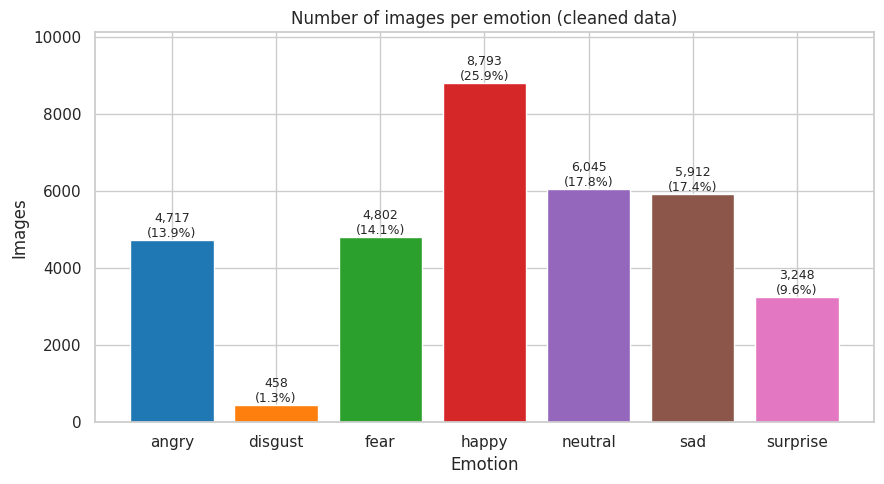

Imbalance ratio (largest / smallest): 19.2x


In [15]:
# Chart - 1 visualization code
counts = df['label'].value_counts().reindex(EMOTIONS)
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(counts.index, counts.values, color=[PALETTE[e] for e in counts.index])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 80, f'{v:,}\n({v / len(df):.1%})', ha='center', fontsize=9)
ax.set(title='Number of images per emotion (cleaned data)', xlabel='Emotion', ylabel='Images', ylim=(0, counts.max() * 1.15))
plt.tight_layout()
plt.show()
print(f'Imbalance ratio (largest / smallest): {counts.max() / counts.min():.1f}x')

##### 1. Why did you pick the specific chart?

A bar chart is the standard way to compare category sizes. Showing both the count and the percentage on each bar makes the imbalance visible immediately, and it is the first thing to check for any classification target.

##### 2. What is/are the insight(s) found from the chart?

* **Happy is the largest class (8,793 images, 25.9%)**, followed by neutral (6,045, 17.8%) and sad (5,912, 17.4%).
* **Disgust is tiny: 458 images, 1.3%**, which is **19.2x smaller than happy**. Surprise (3,248, 9.6%) is also under-represented; fear (4,802, 14.1%) and angry (4,717, 13.9%) sit in the middle.
* Happy, neutral and sad together make up about 61% of the data.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** knowing the imbalance early lets us plan class-weighted loss, oversampling or targeted augmentation, and choose macro-F1 and per-class recall instead of plain accuracy. This protects rare but valuable signals such as disgust and fear in mental-health or customer-service use cases.

**Negative if ignored:** a model could reach roughly 60% accuracy just by favouring happy/neutral/sad while almost never predicting disgust. That would look good in a report but fail exactly where emotion detection matters (e.g. detecting distress).

#### Chart - 2 - Train vs validation split size (Univariate)

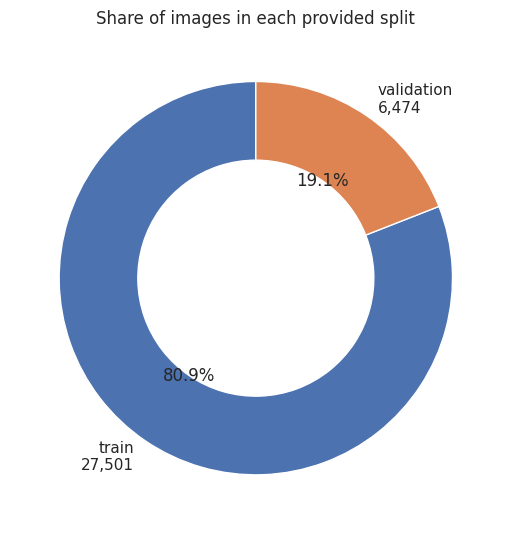

In [16]:
# Chart - 2 visualization code
split_counts = df['split'].value_counts().reindex(['train', 'validation'])
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.pie(split_counts.values, labels=[f'{k}\n{v:,}' for k, v in split_counts.items()], autopct='%1.1f%%',
       startangle=90, colors=['#4c72b0', '#dd8452'], wedgeprops=dict(width=0.4, edgecolor='white'))
ax.set_title('Share of images in each provided split')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A donut chart shows part-to-whole proportions and works well for only two categories. The question is simply how the data is divided between training and validation.

##### 2. What is/are the insight(s) found from the chart?

* After cleaning, **27,501 images (80.9%) are for training and 6,474 (19.1%) for validation**, close to a standard 80/20 split.
* Because the provided validation set is only about 6.5k images and the rarest class (disgust) has just 82 validation images, per-class validation metrics for disgust will be noisy.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the split ratio is healthy for training a CNN, and 6,474 validation images are enough for stable overall metrics.

**Negative:** with only 82 disgust images in validation, a single misclassified image moves disgust recall by about 1.2 percentage points, so conclusions about that class must be drawn carefully (confidence intervals, or merging train+validation for cross-validation). In the ML notebook the provided validation split should be kept as an untouched test set and a validation set carved out of training.

#### Chart - 3 - Brightness distribution (Univariate)

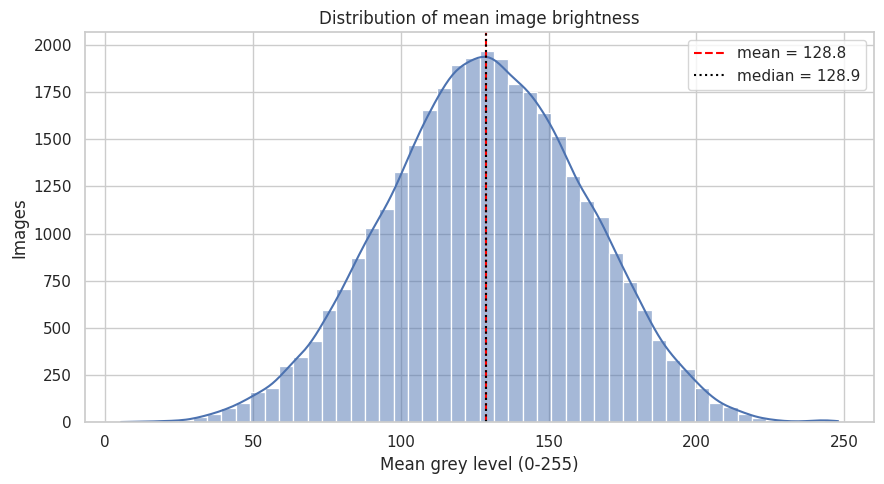

count    33975.00
mean       128.83
std         33.42
min          5.35
25%        106.16
50%        128.88
75%        152.01
max        247.95
skewness = -0.04;  images darker than 30: 29,  brighter than 220: 55


In [17]:
# Chart - 3 visualization code
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(df['brightness'], bins=50, kde=True, color='#4c72b0', ax=ax)
ax.axvline(df['brightness'].mean(), color='red', ls='--', label=f"mean = {df['brightness'].mean():.1f}")
ax.axvline(df['brightness'].median(), color='black', ls=':', label=f"median = {df['brightness'].median():.1f}")
ax.set(title='Distribution of mean image brightness', xlabel='Mean grey level (0-255)', ylabel='Images')
ax.legend()
plt.tight_layout()
plt.show()
print(df['brightness'].describe().round(2).to_string())
print(f"skewness = {df['brightness'].skew():.2f};  images darker than 30: {(df['brightness'] < 30).sum()},  brighter than 220: {(df['brightness'] > 220).sum()}")

##### 1. Why did you pick the specific chart?

A histogram with a density curve shows the shape, centre and spread of a single numeric variable, which tells us whether lighting is consistent across the dataset.

##### 2. What is/are the insight(s) found from the chart?

* Brightness is **almost perfectly symmetric (skewness about -0.04)** with mean about 128.8 and standard deviation about 33.4.
* The middle half of images lies between roughly **106 and 152**, but the full range is very wide (**5 to 248**): a few images are almost black or almost white (29 darker than 30, 55 brighter than 220).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** lighting varies a lot, so brightness/contrast augmentation will help the CNN become robust to real-world conditions such as webcams, dim rooms and strong sunlight.

**Negative:** the extremes (very dark or washed-out faces) contain little expression information and may add noise. They are rare (about 0.25% of images), so they are not removed, but they are a likely source of errors in deployment.

#### Chart - 4 - Contrast distribution (Univariate)

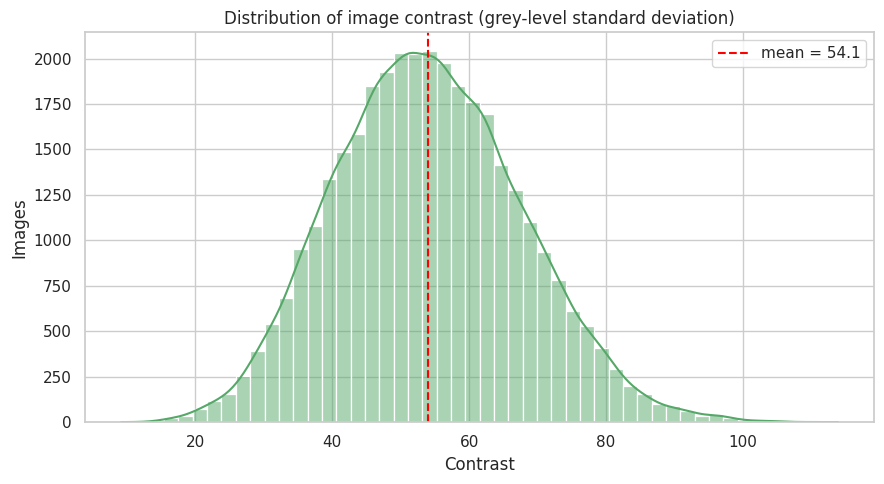

count    33975.00
mean        54.06
std         13.64
min          9.14
25%         44.50
50%         53.62
75%         63.13
max        113.93
skewness = 0.21;  images with contrast below 20: 82


In [18]:
# Chart - 4 visualization code
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(df['contrast'], bins=50, kde=True, color='#55a868', ax=ax)
ax.axvline(df['contrast'].mean(), color='red', ls='--', label=f"mean = {df['contrast'].mean():.1f}")
ax.set(title='Distribution of image contrast (grey-level standard deviation)', xlabel='Contrast', ylabel='Images')
ax.legend()
plt.tight_layout()
plt.show()
print(df['contrast'].describe().round(2).to_string())
print(f"skewness = {df['contrast'].skew():.2f};  images with contrast below 20: {(df['contrast'] < 20).sum()}")

##### 1. Why did you pick the specific chart?

Contrast is a second, independent view of image quality (brightness only tells us the average level). A histogram again shows shape and outliers.

##### 2. What is/are the insight(s) found from the chart?

* Contrast is roughly bell-shaped with a mild right skew (**skewness 0.21**), mean about **54.1**, standard deviation about **13.6**, range about **9 to 114**.
* Only **82 images (0.24%)** have contrast below 20, i.e. look flat and washed out.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** most images have usable contrast, so facial structure (eyes, brows, mouth) is visible; standardising each image (subtract its mean, divide by its standard deviation) is a safe preprocessing step that removes this nuisance variation.

**Negative:** the few flat, low-contrast images are hard for any model; they are too few to hurt training, but they will be misclassified more often at inference time.

#### Chart - 5 - Edge density distribution (Univariate)

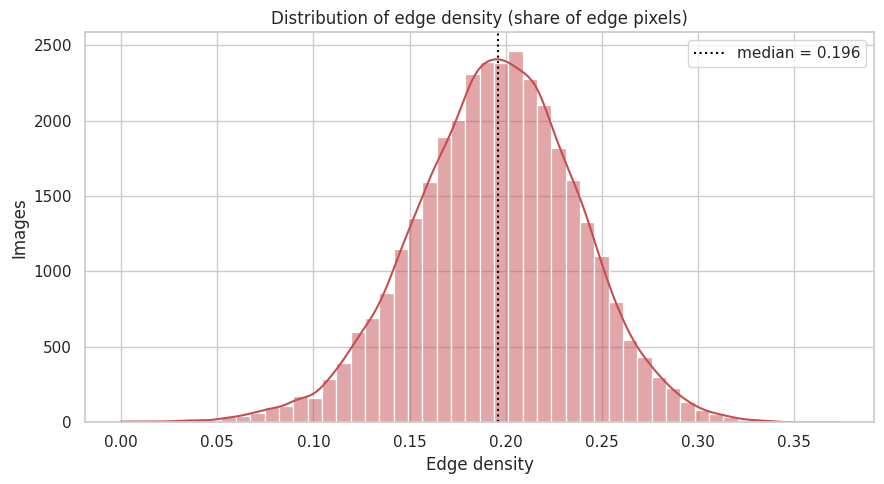

count    33975.000
mean         0.195
std          0.043
min          0.000
25%          0.167
50%          0.196
75%          0.224
max          0.373
skewness = -0.21


In [19]:
# Chart - 5 visualization code
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(df['edge_density'], bins=50, kde=True, color='#c44e52', ax=ax)
ax.axvline(df['edge_density'].median(), color='black', ls=':', label=f"median = {df['edge_density'].median():.3f}")
ax.set(title='Distribution of edge density (share of edge pixels)', xlabel='Edge density', ylabel='Images')
ax.legend()
plt.tight_layout()
plt.show()
print(df['edge_density'].describe().round(3).to_string())
print(f"skewness = {df['edge_density'].skew():.2f}")

##### 1. Why did you pick the specific chart?

Edge density is a proxy for how much structure (wrinkles, mouth and eye outlines) an image contains. A histogram shows whether this is uniform across images.

##### 2. What is/are the insight(s) found from the chart?

* Edge density is concentrated around **0.17-0.22** (median about 0.20, middle 50% of images), with a slight left skew (**-0.21**) and a maximum of **0.37**.
* About a fifth of all pixels are edges in a typical image, so these small faces are visually 'busy' despite their low resolution.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** consistent edge content means the CNN will receive similar amounts of structure from every sample, which supports stable training.

**Negative:** at 48x48 resolution, a fifth of the pixels being edges means fine details are very compressed; aggressive downscaling or blurring augmentation could destroy the subtle cues that separate similar emotions.

#### Chart - 6 - Sharpness distribution, log scale (Univariate)

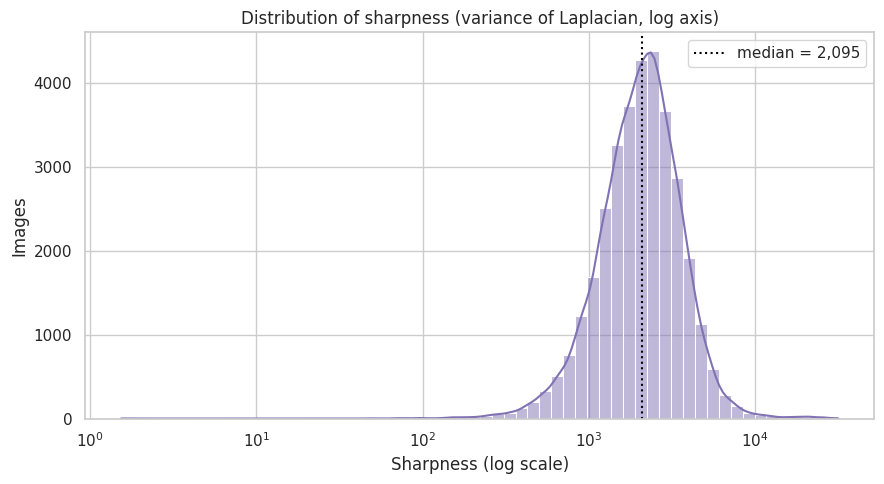

count    33975.0
mean      2376.8
std       1589.2
min          1.5
25%       1441.6
50%       2094.6
75%       2928.1
max      31771.7
skewness = 4.89


In [20]:
# Chart - 6 visualization code
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(df['sharpness'], bins=60, log_scale=True, kde=True, color='#8172b3', ax=ax)
ax.axvline(df['sharpness'].median(), color='black', ls=':', label=f"median = {df['sharpness'].median():,.0f}")
ax.set(title='Distribution of sharpness (variance of Laplacian, log axis)', xlabel='Sharpness (log scale)', ylabel='Images')
ax.legend()
plt.tight_layout()
plt.show()
print(df['sharpness'].describe().round(1).to_string())
print(f"skewness = {df['sharpness'].skew():.2f}")

##### 1. Why did you pick the specific chart?

Sharpness values span several orders of magnitude, so a log axis is needed to see the real shape; on a linear axis almost everything would be squeezed against the left edge.

##### 2. What is/are the insight(s) found from the chart?

* Sharpness is **extremely right-skewed (skewness 4.9)**: median about **2,095**, mean about 2,377 and a maximum of about **31,772**.
* On the log scale the distribution is roughly bell-shaped, so image sharpness varies by a factor of ten or more between images (blurry vs crisp sources).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the large variation justifies mild blur and sharpness augmentation, which makes the model less dependent on image source quality.

**Negative:** raw sharpness is skewed and would need a log transform if it were ever used as a tabular feature; the extreme high values may be noisy or artefact-heavy images (e.g. watermarks, text overlays).

#### Chart - 7 - Brightness by emotion (Bivariate: numerical vs categorical)

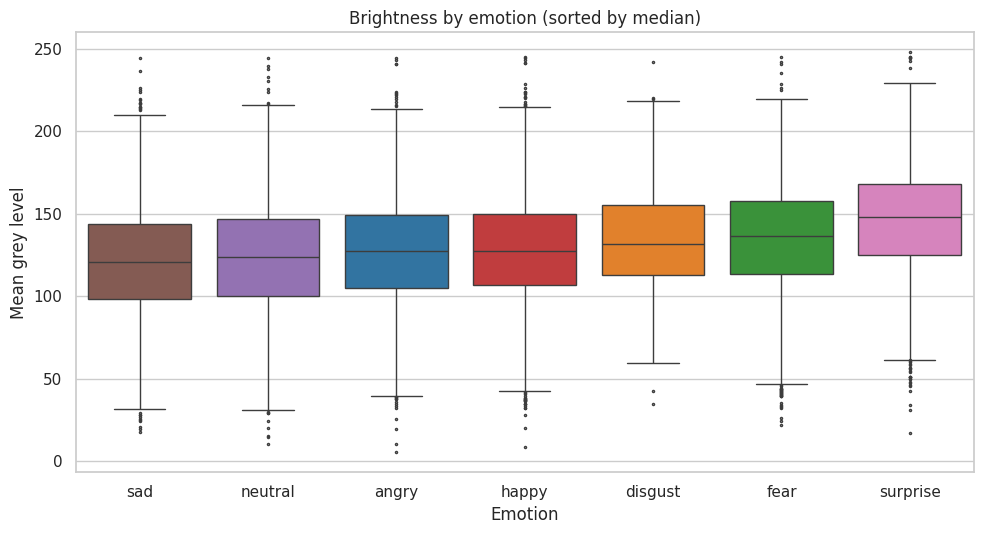

brightness: Kruskal-Wallis H = 1489.5, p = 0.00e+00; emotion explains 4.41% of the variance (eta-squared)
label
sad         120.98
neutral     123.75
angry       127.37
happy       127.58
disgust     131.52
fear        136.72
surprise    147.78


In [21]:
# Chart - 7 visualization code
order = df.groupby('label')['brightness'].median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.boxplot(data=df, x='label', y='brightness', order=order, palette=PALETTE, fliersize=1.5, ax=ax)
ax.set(title='Brightness by emotion (sorted by median)', xlabel='Emotion', ylabel='Mean grey level')
plt.tight_layout()
plt.show()
kruskal_eta('brightness')

##### 1. Why did you pick the specific chart?

A box plot compares the median, spread and outliers of a numeric variable across several categories at once, and sorting by median makes the ranking easy to read.

##### 2. What is/are the insight(s) found from the chart?

* Median brightness ranks **sad (121.0) < neutral (123.8) < angry (127.4) ~ happy (127.6) < disgust (131.5) < fear (136.7) < surprise (147.8)**.
* Surprise images are about **27 grey levels brighter than sad** images. A plausible reason is that wide-open eyes and mouths expose bright sclera and teeth, but this is a hypothesis, not something the chart proves.
* The differences are statistically significant (Kruskal-Wallis p < 0.001) but **emotion explains only 4.4% of brightness variance**: the spread within each emotion (std about 32-33) is far larger than the gaps between medians.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** brightness augmentation is clearly justified, and it is the strongest simple signal in the data.

**Negative / risk:** because surprise is brighter on average, a model could learn a **shortcut (bright face = surprise)** that fails under different lighting. This would hurt real-world accuracy. Brightness jitter, per-image normalisation and checking per-class errors on dark/bright subsets mitigate it.

#### Chart - 8 - Contrast by emotion (Bivariate: numerical vs categorical)

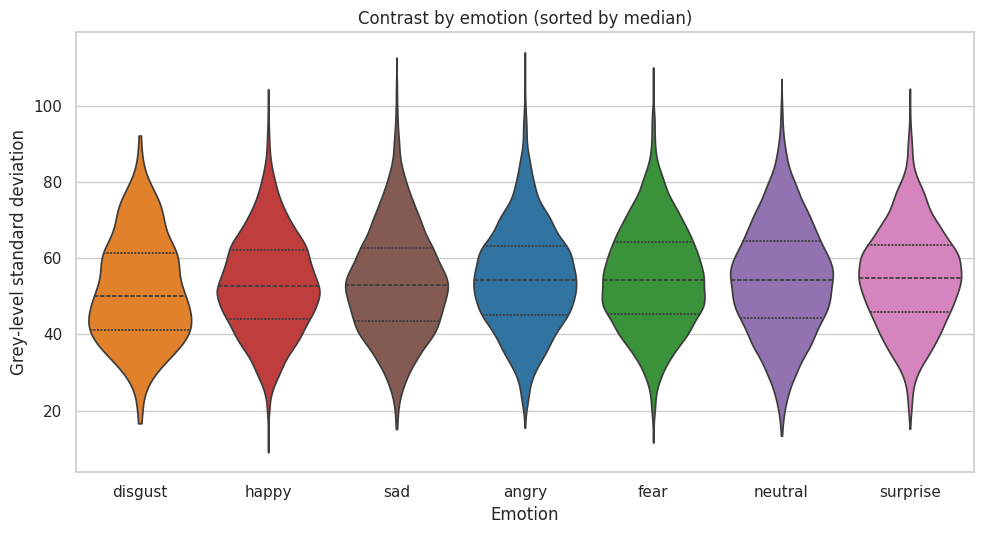

contrast: Kruskal-Wallis H = 106.9, p = 8.88e-21; emotion explains 0.29% of the variance (eta-squared)
label
disgust     50.02
happy       52.63
sad         52.84
angry       54.19
fear        54.33
neutral     54.35
surprise    54.87


In [22]:
# Chart - 8 visualization code
order = df.groupby('label')['contrast'].median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.violinplot(data=df, x='label', y='contrast', order=order, palette=PALETTE, cut=0, inner='quartile', ax=ax)
ax.set(title='Contrast by emotion (sorted by median)', xlabel='Emotion', ylabel='Grey-level standard deviation')
plt.tight_layout()
plt.show()
kruskal_eta('contrast')

##### 1. Why did you pick the specific chart?

A violin plot shows the full distribution shape for each class (not just quartiles), which helps judge whether the distributions really differ or just have different tails.

##### 2. What is/are the insight(s) found from the chart?

* Median contrast only ranges from **about 50.0 (disgust) to 54.9 (surprise)**; the violins have almost identical shapes.
* The Kruskal-Wallis test is significant (p about 1e-20) only because of the large sample, while **emotion explains just 0.3% of contrast variance**. This is a clear example of **statistical vs practical significance**.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** contrast carries almost no emotion information, so normalising it away (per-image standardisation) is safe and removes nuisance variation without losing signal.

**Negative:** none for the model, but engineering contrast as a feature would waste effort; no business value is gained from it.

#### Chart - 9 - Edge density by emotion (Bivariate: numerical vs categorical)

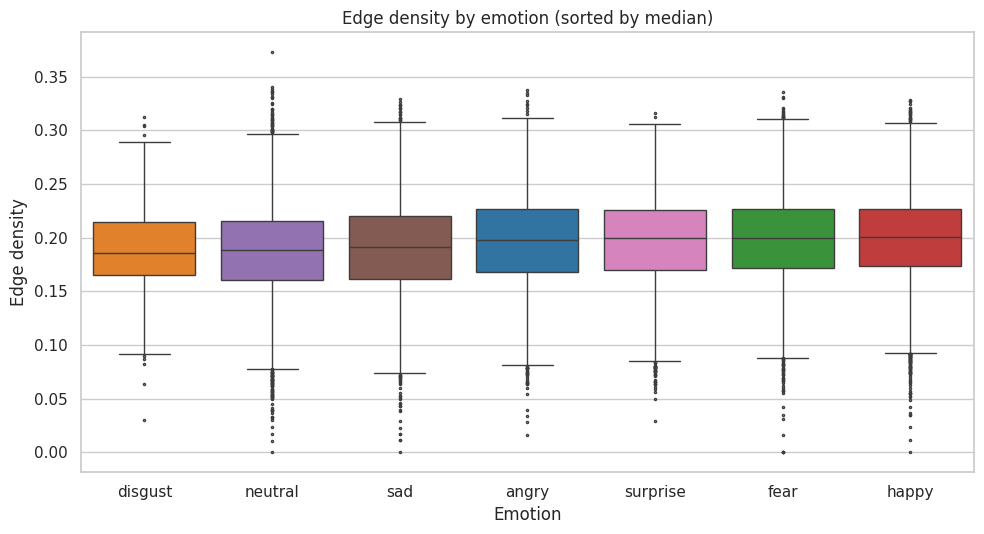

edge_density: Kruskal-Wallis H = 399.8, p = 3.14e-83; emotion explains 1.07% of the variance (eta-squared)
label
disgust     0.19
neutral     0.19
sad         0.19
angry       0.20
surprise    0.20
fear        0.20
happy       0.20


In [23]:
# Chart - 9 visualization code
order = df.groupby('label')['edge_density'].median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.boxplot(data=df, x='label', y='edge_density', order=order, palette=PALETTE, fliersize=1.5, ax=ax)
ax.set(title='Edge density by emotion (sorted by median)', xlabel='Emotion', ylabel='Edge density')
plt.tight_layout()
plt.show()
kruskal_eta('edge_density')

##### 1. Why did you pick the specific chart?

Same box-plot logic as chart 7: we want to know whether the amount of edge structure differs between expressions (for example, more wrinkles when angry or disgusted).

##### 2. What is/are the insight(s) found from the chart?

* Median edge density is **0.19-0.20 for every emotion**; the boxes overlap almost completely.
* Emotion explains only **1.1% of the variance**, so the overall amount of edges does not separate emotions; what matters is **where** the edges are (mouth, brows, eyes), not how many.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it confirms that global statistics are weak features and that a CNN that learns **spatial** patterns is the right tool.

**Negative:** hand-crafted global edge features would not help a classical model such as logistic regression or an SVM, so a feature-engineering shortcut is not available.

#### Chart - 10 - Median sharpness by emotion (Bivariate: numerical vs categorical)

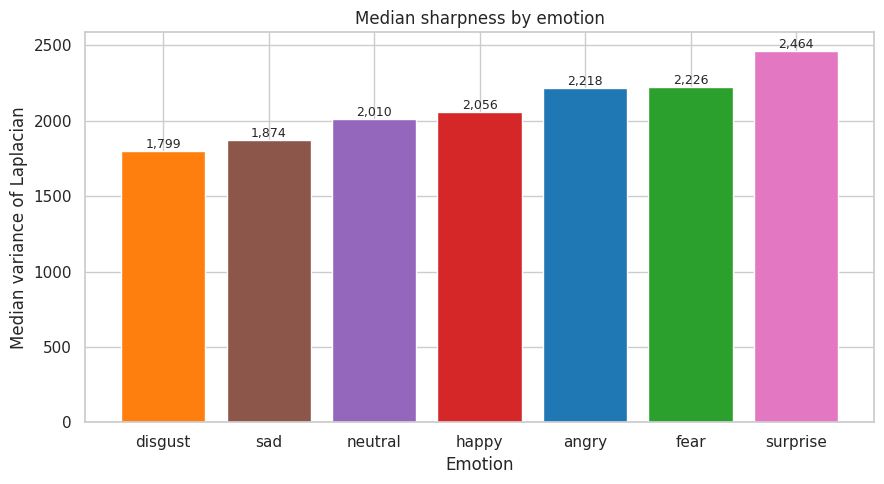

sharpness: Kruskal-Wallis H = 656.7, p = 1.37e-138; emotion explains 1.38% of the variance (eta-squared)
label
disgust     1799.43
sad         1874.16
neutral     2009.87
happy       2055.65
angry       2217.88
fear        2226.34
surprise    2463.91
surprise / disgust median ratio = 1.37


In [24]:
# Chart - 10 visualization code
med = df.groupby('label')['sharpness'].median().sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(med.index, med.values, color=[PALETTE[e] for e in med.index])
for b, v in zip(bars, med.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 20, f'{v:,.0f}', ha='center', fontsize=9)
ax.set(title='Median sharpness by emotion', xlabel='Emotion', ylabel='Median variance of Laplacian')
plt.tight_layout()
plt.show()
kruskal_eta('sharpness')
print(f"surprise / disgust median ratio = {med['surprise'] / med['disgust']:.2f}")

##### 1. Why did you pick the specific chart?

Because sharpness is heavily skewed, medians are a more honest summary than means, and a sorted bar chart makes the ranking clear.

##### 2. What is/are the insight(s) found from the chart?

* Median sharpness runs from **1,799 (disgust) and 1,874 (sad) up to 2,464 (surprise)**; surprise is about **37% sharper than disgust**.
* Emotion explains only **1.4% of sharpness variance** and the within-class spread is large, so this is a weak signal. Open mouths and eyes in surprise and fear create strong local edges, which probably explains the ranking.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it shows that expressions with large facial movements (surprise, fear, angry) produce stronger local detail, supporting the use of architectures that preserve fine spatial detail.

**Negative:** image-quality differences (sharpness) are partly confounded with emotion, so there is a risk of the model learning image-source artefacts; blur/sharpen augmentation reduces that risk.

#### Chart - 11 - Class proportions in train vs validation (Bivariate: categorical vs categorical)

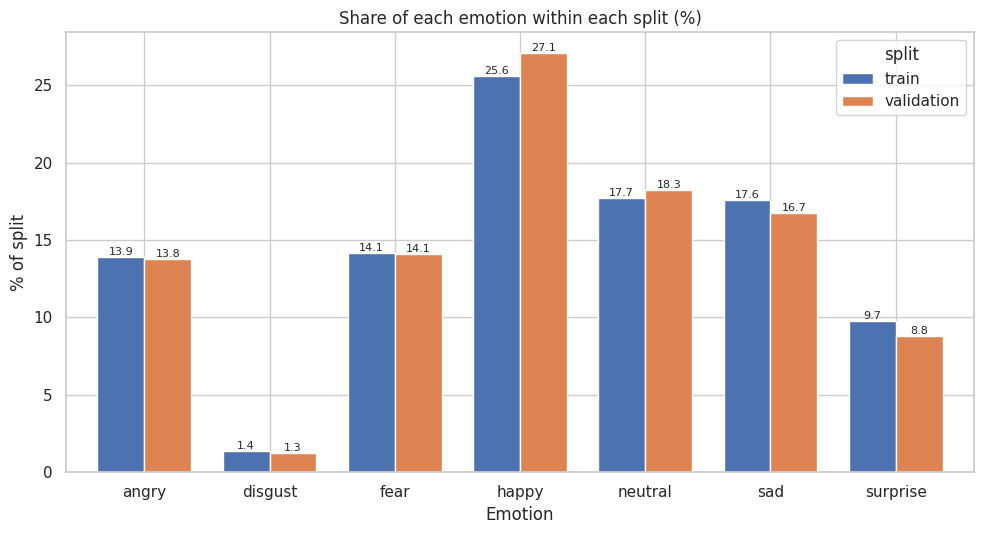

Largest absolute difference between splits: 1.46 percentage points


In [25]:
# Chart - 11 visualization code
share = (df.groupby('split')['label'].value_counts(normalize=True).unstack(0).reindex(EMOTIONS) * 100)
ax = share[['train', 'validation']].plot.bar(figsize=(10, 5.5), color=['#4c72b0', '#dd8452'], width=0.75)
for c in ax.containers:
    ax.bar_label(c, fmt='%.1f', fontsize=8)
ax.set(title='Share of each emotion within each split (%)', xlabel='Emotion', ylabel='% of split')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
print('Largest absolute difference between splits: %.2f percentage points' % (share['train'] - share['validation']).abs().max())

##### 1. Why did you pick the specific chart?

A grouped bar chart compares two categorical distributions side by side, which is exactly what is needed to check whether the validation set is representative of the training set.

##### 2. What is/are the insight(s) found from the chart?

* The splits are **well stratified**: every class share differs by **at most about 1.5 percentage points** (largest gap: happy 25.6% in train vs 27.1% in validation); disgust is 1.4% vs 1.3%.
* Both splits inherit the same imbalance: **happy + neutral + sad make up about 62% of validation**.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** validation metrics are comparable with training metrics and a model will not be judged on a different mix of emotions.

**Negative:** because validation is also dominated by three classes, overall accuracy is dominated by them as well and will hide weak performance on disgust, surprise and fear. Macro-averaged metrics are required.

#### Chart - 12 - Left-right asymmetry by emotion (Bivariate: numerical vs categorical)

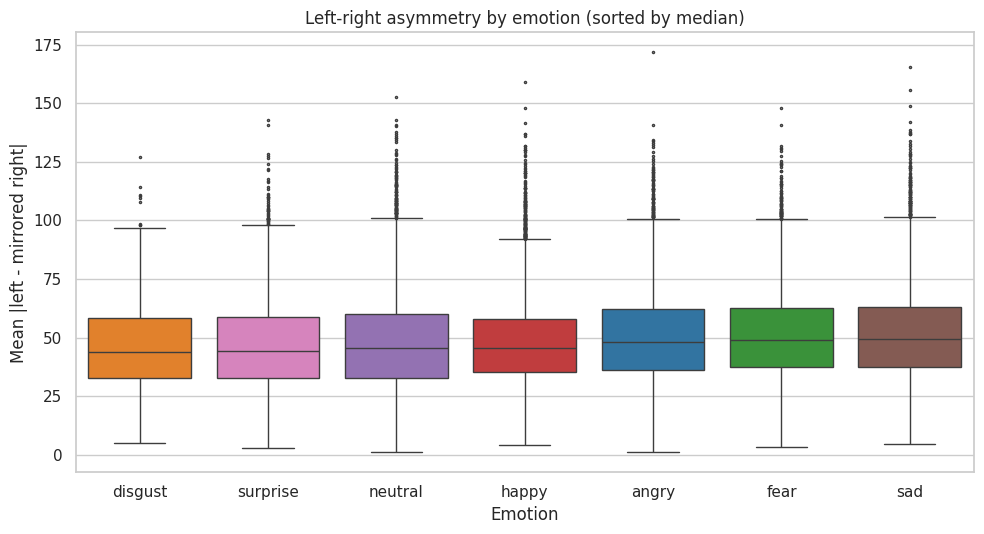

left_right_asym: Kruskal-Wallis H = 309.3, p = 8.49e-64; emotion explains 0.84% of the variance (eta-squared)
label
disgust     44.01
surprise    44.50
neutral     45.49
happy       45.50
angry       48.12
fear        49.15
sad         49.34
correlation of asymmetry with contrast: 0.63


In [26]:
# Chart - 12 visualization code
order = df.groupby('label')['left_right_asym'].median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.boxplot(data=df, x='label', y='left_right_asym', order=order, palette=PALETTE, fliersize=1.5, ax=ax)
ax.set(title='Left-right asymmetry by emotion (sorted by median)', xlabel='Emotion', ylabel='Mean |left - mirrored right|')
plt.tight_layout()
plt.show()
kruskal_eta('left_right_asym')
print(f"correlation of asymmetry with contrast: {df['left_right_asym'].corr(df['contrast']):.2f}")

##### 1. Why did you pick the specific chart?

Asymmetry tests an anatomical idea (are some expressions less symmetric?) and also tells us whether horizontal-flip augmentation is realistic. A box plot compares the classes.

##### 2. What is/are the insight(s) found from the chart?

* Median asymmetry is about **44.0 (disgust), 44.5 (surprise), 45.5 (neutral, happy), 48.1 (angry), 49.2 (fear), 49.3 (sad)**; emotion explains only **0.8%** of the variance.
* Faces are far from symmetric in pixel terms (typical difference about 47 grey levels), and asymmetry is strongly tied to image contrast (**r = 0.63**), so it mostly reflects **pose and lighting rather than the expression itself**.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** because real faces vary in pose and lighting anyway, **horizontal-flip augmentation is label-preserving and realistic**, effectively doubling the variety of every class at no cost.

**Negative:** asymmetry is not a useful emotion feature, and a model that leans on lighting direction would generalise poorly; flips and brightness jitter help reduce that dependency.

#### Chart - 13 - Upper vs lower face brightness by emotion (Bivariate: numerical vs categorical)

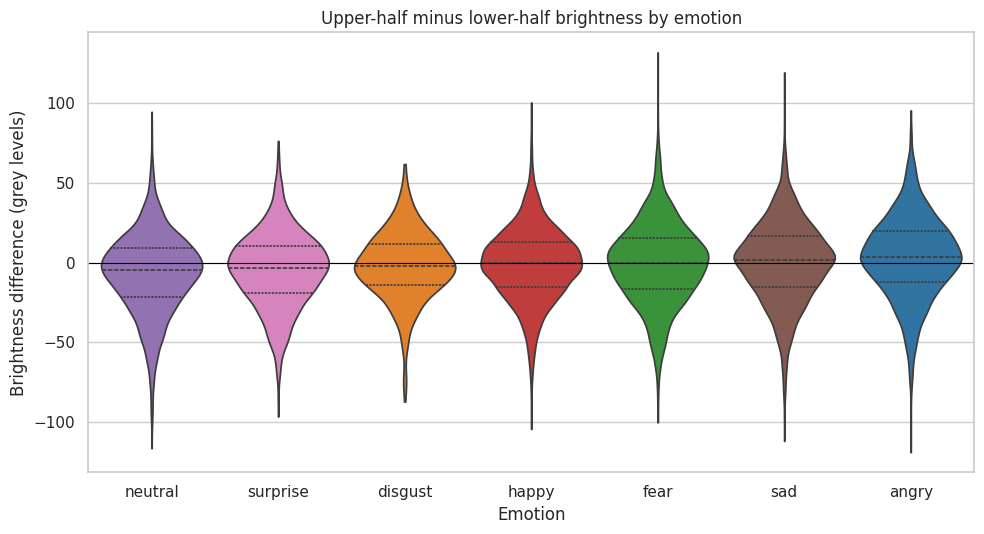

upper_lower: Kruskal-Wallis H = 511.4, p = 3.01e-107; emotion explains 1.57% of the variance (eta-squared)
label
neutral    -4.69
surprise   -3.15
disgust    -1.87
happy      -0.42
fear        0.14
sad         1.54
angry       3.78


In [27]:
# Chart - 13 visualization code
order = df.groupby('label')['upper_lower'].median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.violinplot(data=df, x='label', y='upper_lower', order=order, palette=PALETTE, cut=0, inner='quartile', ax=ax)
ax.axhline(0, color='black', lw=0.8)
ax.set(title='Upper-half minus lower-half brightness by emotion', xlabel='Emotion', ylabel='Brightness difference (grey levels)')
plt.tight_layout()
plt.show()
kruskal_eta('upper_lower')

##### 1. Why did you pick the specific chart?

Expressions act on different facial regions (brows and eyes on top, mouth at the bottom). Comparing the brightness of the top and bottom halves is a simple way to see if regional differences exist; a violin plot shows the full spread around zero.

##### 2. What is/are the insight(s) found from the chart?

* Medians run from **+3.8 (angry) and +1.5 (sad) through about 0 (fear, happy) to -1.9 (disgust), -3.2 (surprise) and -4.7 (neutral)**: an 8.5 grey-level gap between angry and neutral.
* Emotion explains **1.6%** of the variance, the highest among the non-brightness features, but the spread (std about 25) dwarfs the gaps. A possible reading is that frowning brows shade the upper face while open mouths with visible teeth brighten the lower face, but lighting direction is a competing explanation.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it supports the idea that emotion information is **regional**: the eyes/brow and mouth areas should be preserved, so aggressive cropping or heavy random erasing should be avoided.

**Negative:** top-down lighting is a confounder, and without lighting augmentation the model might use shading instead of expression.

#### Chart - 14 - Share of duplicated images by emotion, raw data (Bivariate: categorical vs categorical)

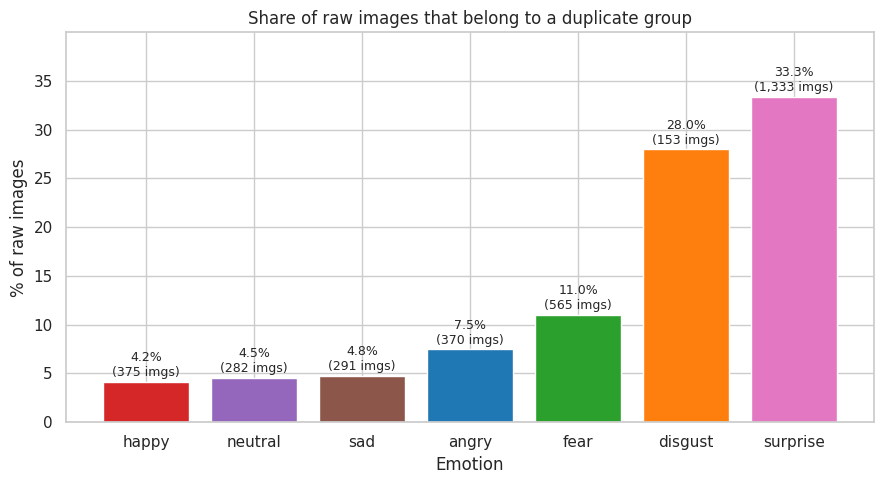

In [28]:
# Chart - 14 visualization code (uses the RAW data before cleaning)
in_dup_group = df_raw.duplicated('img_hash', keep=False)
dup_pct = (in_dup_group.groupby(df_raw['label']).mean() * 100).reindex(EMOTIONS).sort_values()
dup_n = in_dup_group.groupby(df_raw['label']).sum().reindex(dup_pct.index)
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(dup_pct.index, dup_pct.values, color=[PALETTE[e] for e in dup_pct.index])
for b, p, n in zip(bars, dup_pct.values, dup_n.values):
    ax.text(b.get_x() + b.get_width() / 2, p + 0.6, f'{p:.1f}%\n({n:,} imgs)', ha='center', fontsize=9)
ax.set(title='Share of raw images that belong to a duplicate group', xlabel='Emotion', ylabel='% of raw images', ylim=(0, dup_pct.max() * 1.2))
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart of percentages (not counts) is needed because the classes have different sizes; a raw count would hide that duplication is a much bigger problem for small classes.

##### 2. What is/are the insight(s) found from the chart?

* **33.3% of surprise images and 28.0% of disgust images belong to duplicate groups**, versus 11.0% for fear, 7.5% for angry and only about 4.2-4.8% for happy, neutral and sad.
* Duplication is **concentrated in exactly the classes that are already under-represented**, so a model trained on the raw data would see surprise and disgust inflated by repeated copies.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** removing duplicates prevents memorisation and inflated validation scores, so reported accuracy will reflect real performance; this is the most important data-quality fix in the project.

**Negative:** after cleaning, surprise loses about 16% of its training images and the class imbalance widens. This has to be compensated with augmentation or class weighting, otherwise cleaning would slightly hurt the minority classes.

#### Chart - 15 - Sample images per emotion (Bivariate: image vs categorical)

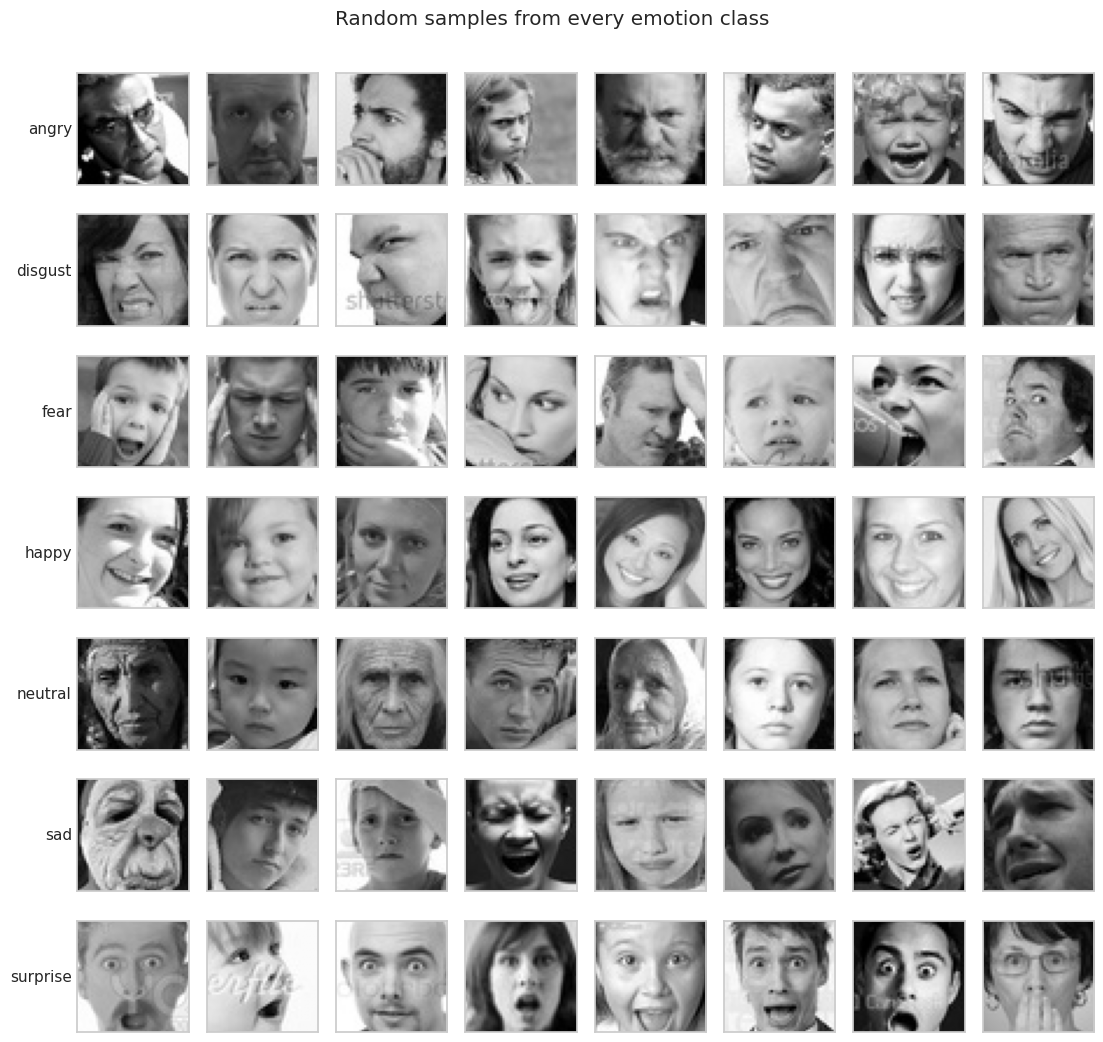

In [29]:
# Chart - 15 visualization code
rng = np.random.RandomState(RANDOM_STATE)
n_cols = 8
fig, axes = plt.subplots(len(EMOTIONS), n_cols, figsize=(n_cols * 1.4, len(EMOTIONS) * 1.5))
for i, emo in enumerate(EMOTIONS):
    paths = df.loc[df['label'] == emo, 'path'].sample(n_cols, random_state=RANDOM_STATE).values
    for j, p in enumerate(paths):
        axes[i, j].imshow(cv2.imread(p, cv2.IMREAD_GRAYSCALE), cmap='gray', vmin=0, vmax=255)
        axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
        if j == 0:
            axes[i, j].set_ylabel(emo, rotation=0, ha='right', va='center', fontsize=11)
fig.suptitle('Random samples from every emotion class', y=1.0)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

Statistics cannot show label noise, occlusion or pose variation, so looking at real examples is an essential qualitative check before modelling.

##### 2. What is/are the insight(s) found from the chart?

* Images are tightly cropped, roughly centred faces of **all ages (babies to older adults)**.
* Real-world difficulties are visible: **profile and tilted views, glasses, hands covering the face, watermarks, a drawing among photographs, and very dark or very bright frames**.
* Some labels look **ambiguous** (for example expressions that could be read as angry, fear or surprise), which suggests an accuracy ceiling below 100% caused by label noise.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the diversity of the data is good for building a robust model, and the examples justify rotation, flip and brightness augmentation.

**Negative:** label noise and occlusion put a ceiling on achievable accuracy, and non-photographic items such as drawings and watermarks add noise; business users should be told that expected accuracy is limited, especially for fear vs surprise and sad vs neutral.

#### Chart - 16 - Average face per emotion (Bivariate: image vs categorical)

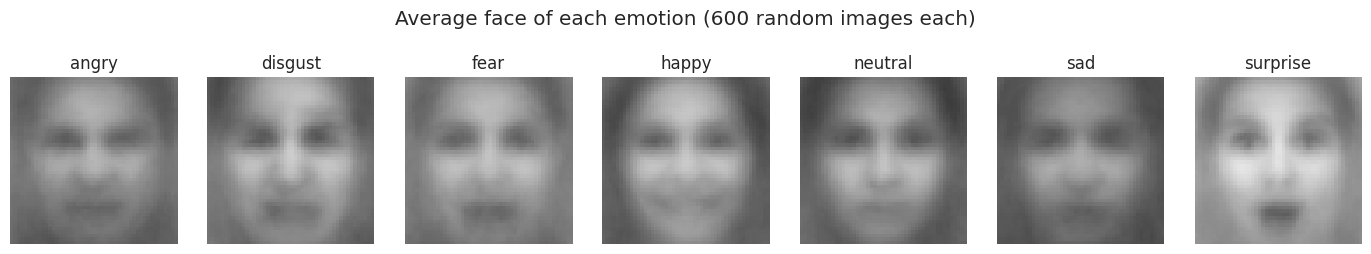

Mean absolute pixel difference from the neutral average face:
neutral      0.0
happy        6.6
sad          6.6
angry        7.6
disgust      9.8
fear        10.6
surprise    22.0


In [30]:
# Chart - 16 visualization code
# Load up to 600 images per emotion once; they are reused by charts 17 and 22.
sample_imgs = {}
for emo in EMOTIONS:
    paths = df.loc[df['label'] == emo, 'path'].sample(min(600, (df['label'] == emo).sum()), random_state=RANDOM_STATE)
    sample_imgs[emo] = np.stack([cv2.imread(p, cv2.IMREAD_GRAYSCALE) for p in paths]).astype(np.float32)
mean_faces = {emo: arr.mean(axis=0) for emo, arr in sample_imgs.items()}

fig, axes = plt.subplots(1, 7, figsize=(14, 2.4))
for ax, emo in zip(axes, EMOTIONS):
    ax.imshow(mean_faces[emo], cmap='gray', vmin=60, vmax=200)
    ax.set_title(emo); ax.axis('off')
fig.suptitle('Average face of each emotion (600 random images each)', y=1.05)
plt.tight_layout()
plt.show()
neutral = mean_faces['neutral']
print('Mean absolute pixel difference from the neutral average face:')
print(pd.Series({e: np.abs(mean_faces[e] - neutral).mean() for e in EMOTIONS}).round(1).sort_values().to_string())

##### 1. Why did you pick the specific chart?

Averaging many faces cancels individual identity and shows what is systematically common to an emotion, which is a direct way to see where in the face the expression information lives.

##### 2. What is/are the insight(s) found from the chart?

* The average faces are **blurry, centred faces with eyes, nose and mouth roughly aligned**, so the crops are reasonably consistent, but individual variation is much larger than expression differences.
* **Surprise is the only average face that clearly stands out**: it is much brighter and shows a dark, open mouth. Measured against the neutral average it differs by about **22.0 grey levels**, then fear (10.6), disgust (9.8), angry (7.6), happy (6.6) and sad (6.6).
* Part of the surprise difference is simply its higher overall brightness (see chart 7).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the subtle differences confirm that a CNN must learn **fine local patterns** in the eye, brow and mouth regions rather than global appearance, which supports deeper models and transfer learning over simple classifiers.

**Negative:** since the average faces of angry, sad and happy are within about 6.6-7.6 grey levels of neutral, these classes are likely to be confused with each other and with neutral, and the model will need good capacity and augmentation to separate them.

#### Chart - 17 - Pixel intensity distribution per emotion (Bivariate: numerical vs categorical)

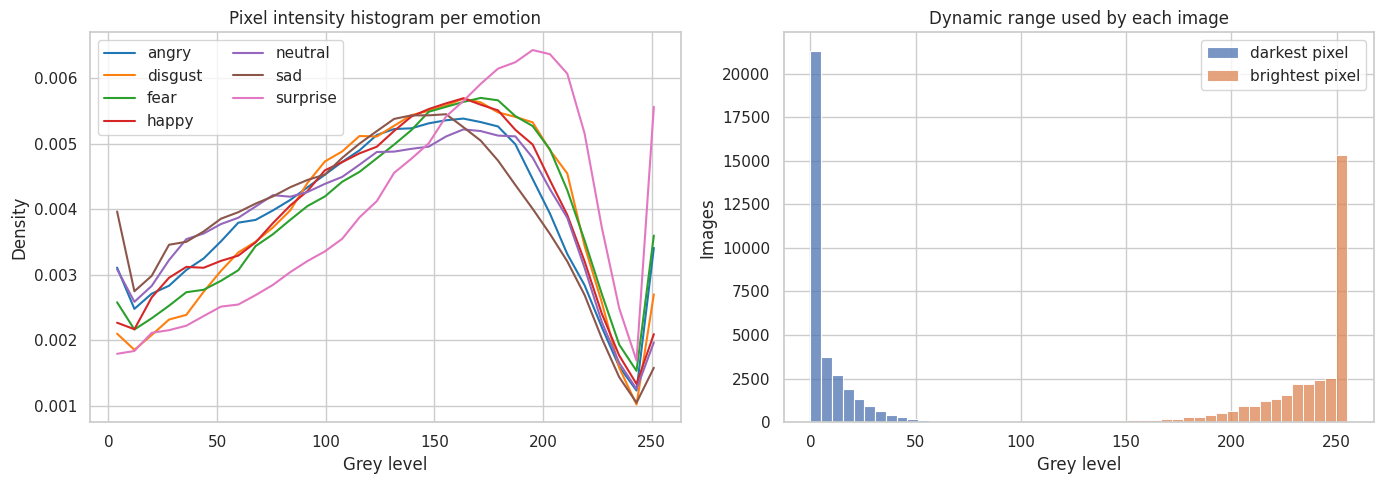

        min_px   max_px
count  33975.0  33975.0
mean       7.8    236.6
std       13.0     24.5
min        0.0     47.0
25%        0.0    226.0
50%        1.0    246.0
75%       11.0    255.0
max      205.0    255.0


In [31]:
# Chart - 17 visualization code
bins = np.linspace(0, 255, 33)
centres = (bins[:-1] + bins[1:]) / 2
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for emo in EMOTIONS:
    hist, _ = np.histogram(sample_imgs[emo].ravel(), bins=bins, density=True)
    axes[0].plot(centres, hist, label=emo, color=PALETTE[emo])
axes[0].set(title='Pixel intensity histogram per emotion', xlabel='Grey level', ylabel='Density')
axes[0].legend(ncol=2)
sns.histplot(df['min_px'], bins=40, color='#4c72b0', label='darkest pixel', ax=axes[1])
sns.histplot(df['max_px'], bins=40, color='#dd8452', label='brightest pixel', ax=axes[1])
axes[1].set(title='Dynamic range used by each image', xlabel='Grey level', ylabel='Images')
axes[1].legend()
plt.tight_layout()
plt.show()
print(df[['min_px', 'max_px']].describe().round(1).to_string())

##### 1. Why did you pick the specific chart?

Line histograms let several classes be compared on one axis, and the min/max view shows whether images already use the full 0-255 range, which decides if contrast stretching is needed.

##### 2. What is/are the insight(s) found from the chart?

* The pixel histograms of all emotions have **very similar, broad shapes**, with small shifts (surprise is slightly brighter, sad slightly darker).
* **Most images already span almost the full dynamic range**: the median darkest pixel is about 1 and the median brightest pixel is 246; 75% of images have a darkest pixel at or below 11 and a brightest pixel at or above 226.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the images are already contrast-stretched, so **histogram equalisation or extra contrast stretching is unnecessary**; simple scaling to [0, 1] plus standardisation is sufficient, which keeps the preprocessing pipeline fast and simple for real-time use.

**Negative:** none significant; the few images that do not use the full range are the same low-contrast outliers seen in chart 4.

#### Chart - 18 - Train vs validation distribution shift check (Bivariate: numerical vs categorical)

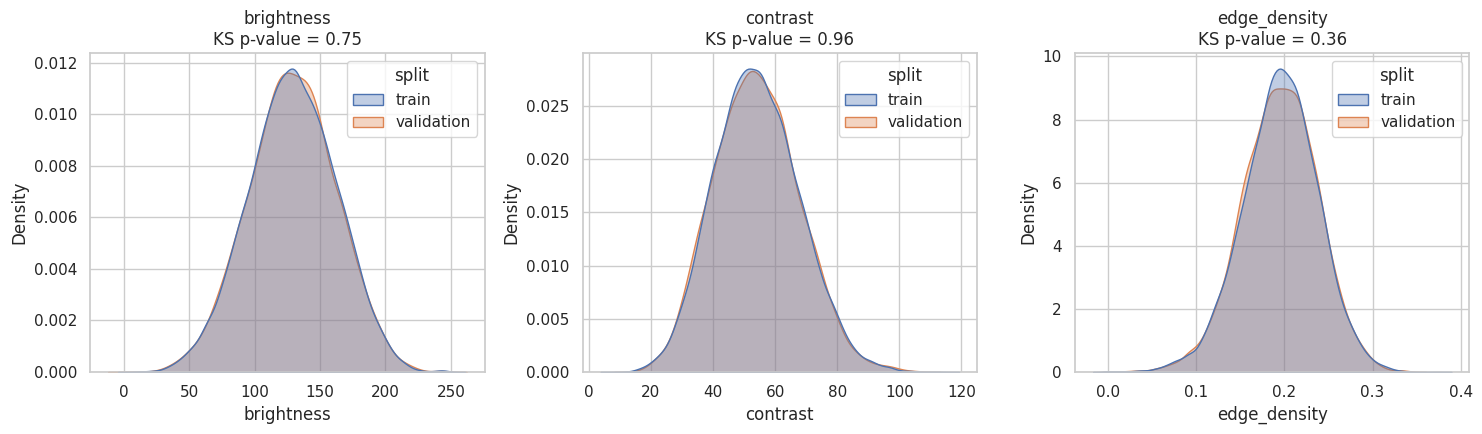

            brightness  contrast  edge_density
split                                         
train          128.864    54.066         0.195
validation     128.682    54.034         0.195


In [32]:
# Chart - 18 visualization code
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, feat in zip(axes, ['brightness', 'contrast', 'edge_density']):
    sns.kdeplot(data=df, x=feat, hue='split', common_norm=False, fill=True, alpha=0.35, ax=ax)
    ks = stats.ks_2samp(df.loc[df['split'] == 'train', feat], df.loc[df['split'] == 'validation', feat])
    ax.set_title(f'{feat}\nKS p-value = {ks.pvalue:.2f}')
plt.tight_layout()
plt.show()
print(df.groupby('split')[['brightness', 'contrast', 'edge_density']].mean().round(3))

##### 1. Why did you pick the specific chart?

Overlaid density plots plus a Kolmogorov-Smirnov test directly answer whether training and validation images come from the same distribution, which is a precondition for trusting validation scores.

##### 2. What is/are the insight(s) found from the chart?

* The train and validation curves **overlap almost perfectly**; mean brightness is **128.9 (train) vs 128.7 (validation)**.
* The KS tests give **p-values of about 0.75 (brightness), 0.96 (contrast) and 0.36 (edge density)**, so there is **no evidence of distribution shift**.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** validation performance should be a fair estimate of performance on similar unseen data, which gives stakeholders reliable numbers.

**Negative:** this only shows that train and validation are alike; both come from the same source, so performance on a different camera, population or lighting setup (a real deployment) may still be lower. Testing on an external dataset is recommended before deployment.

#### Chart - 19 - Correlation heatmap of image features (Multivariate)

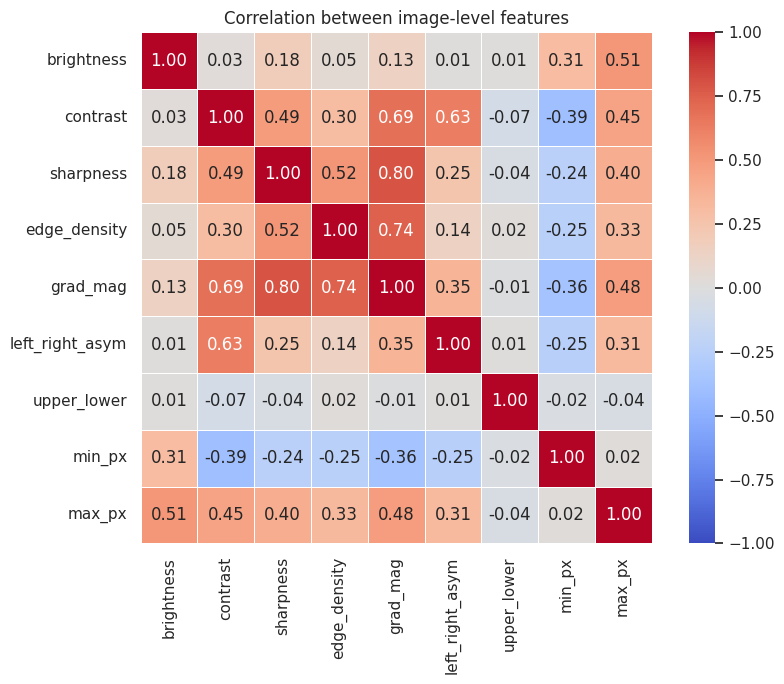

Strongest correlations:
sharpness     grad_mag           0.80
edge_density  grad_mag           0.74
contrast      grad_mag           0.69
              left_right_asym    0.63
sharpness     edge_density       0.52
brightness    max_px             0.51


In [33]:
# Chart - 19 visualization code (Correlation Heatmap)
corr = df[FEATURES].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax)
ax.set_title('Correlation between image-level features')
plt.tight_layout()
plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().sort_values(key=abs, ascending=False)
print('Strongest correlations:')
print(pairs.head(6).round(2).to_string())

##### 1. Why did you pick the specific chart?

A correlation heatmap summarises all pairwise linear relationships in one picture and is the standard tool for spotting redundant features.

##### 2. What is/are the insight(s) found from the chart?

* **Gradient magnitude, sharpness and edge density are strongly related**: grad_mag-sharpness r = 0.80, grad_mag-edge_density r = 0.74, sharpness-edge_density r = 0.52; contrast-grad_mag is 0.69 and contrast-asymmetry is 0.63.
* **Brightness is almost independent of contrast (r = 0.03)** and the upper-lower difference is uncorrelated with everything (|r| <= 0.07).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it guides feature selection: if hand-crafted features are used, keep **brightness, contrast, edge density, upper-lower difference** and drop grad_mag (redundant with sharpness), which reduces multicollinearity and keeps the feature set small and interpretable.

**Negative:** these features are weak predictors (charts 7-13), so even a well-selected set will not match a CNN; they are useful for explanation and data auditing, not as the main model input.

#### Chart - 20 - Pair plot of key features by emotion (Multivariate)

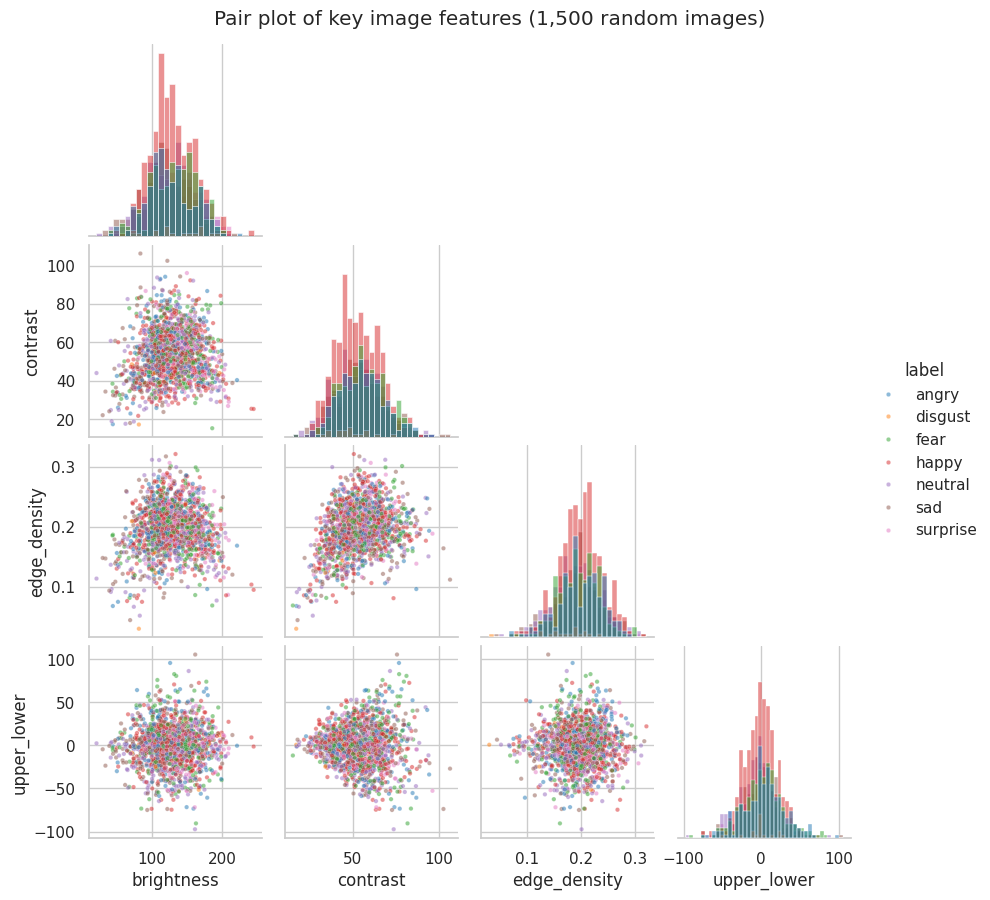

In [34]:
# Chart - 20 visualization code (Pair Plot)
pp_df = df.sample(1500, random_state=RANDOM_STATE)
g = sns.pairplot(pp_df, vars=['brightness', 'contrast', 'edge_density', 'upper_lower'], hue='label', hue_order=EMOTIONS,
                 palette=PALETTE, diag_kind='hist', plot_kws=dict(s=10, alpha=0.5), height=2.2, corner=True)
g.fig.suptitle('Pair plot of key image features (1,500 random images)', y=1.02)
plt.show()

##### 1. Why did you pick the specific chart?

A pair plot shows every two-way relationship between features and, with colour by emotion, reveals at a glance whether the classes form separate clusters.

##### 2. What is/are the insight(s) found from the chart?

* The seven colours **overlap heavily in every panel**; no pair of simple features separates the emotions.
* The only visible tendency is that surprise (high brightness) is shifted slightly to the right in the brightness panels; contrast and brightness show no relationship, as chart 19 predicted.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it provides clear evidence for the modelling decision: classical models on global statistics would perform poorly, so a **CNN on raw pixels** is justified.

**Negative:** it also warns that the classes are hard to separate even for sophisticated models; stakeholders should expect confusion between visually similar emotions.

#### Chart - 21 - PCA projection of raw pixels (Multivariate)

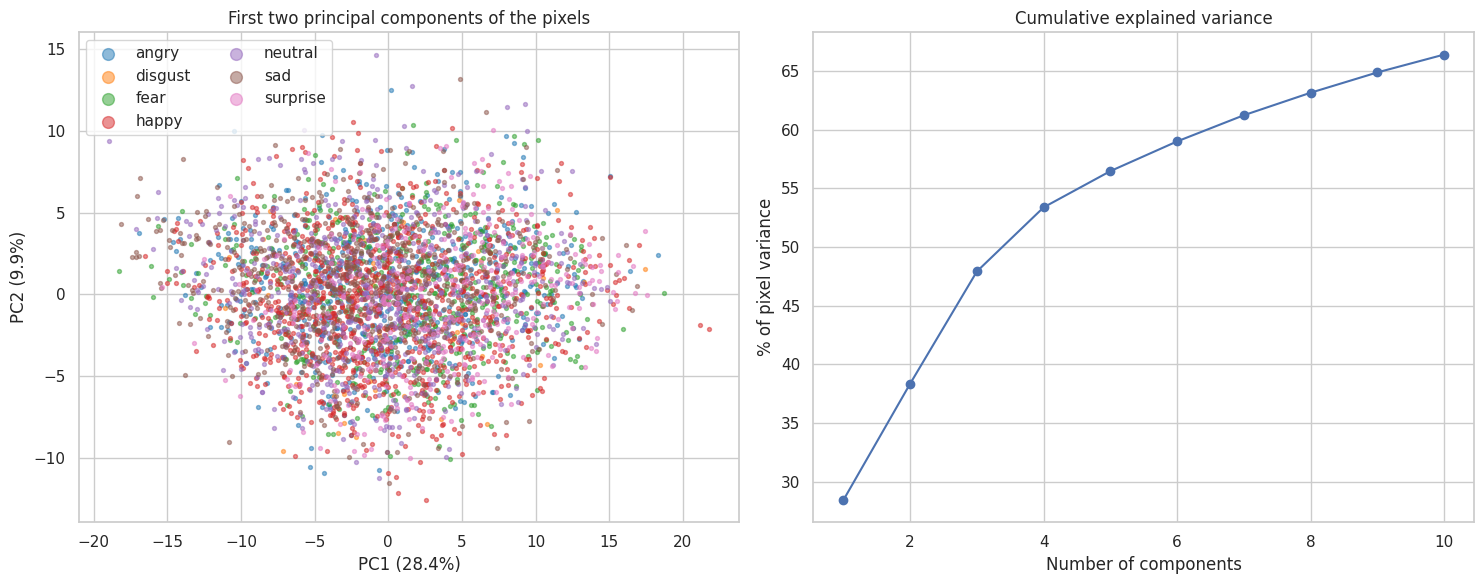

Explained variance of the first 10 components: [28.4 38.4 47.9 53.4 56.5 59.  61.2 63.1 64.9 66.4]
PC1 vs brightness correlation: 0.993
PC2 vs contrast correlation  : -0.290


In [35]:
# Chart - 21 visualization code
pca_df = df.sample(4000, random_state=RANDOM_STATE)
X = np.stack([cv2.imread(p, cv2.IMREAD_GRAYSCALE).ravel() for p in pca_df['path']]).astype(np.float32) / 255.0
pca = PCA(n_components=10, random_state=RANDOM_STATE).fit(X)
Z = pca.transform(X)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for emo in EMOTIONS:
    m = (pca_df['label'] == emo).values
    axes[0].scatter(Z[m, 0], Z[m, 1], s=8, alpha=0.5, label=emo, color=PALETTE[emo])
axes[0].set(title='First two principal components of the pixels', xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.1%})', ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
axes[0].legend(markerscale=3, ncol=2)
axes[1].plot(range(1, 11), np.cumsum(pca.explained_variance_ratio_) * 100, marker='o')
axes[1].set(title='Cumulative explained variance', xlabel='Number of components', ylabel='% of pixel variance')
plt.tight_layout()
plt.show()
print('Explained variance of the first 10 components:', (np.cumsum(pca.explained_variance_ratio_) * 100).round(1))
print(f"PC1 vs brightness correlation: {np.corrcoef(Z[:, 0], pca_df['brightness'])[0, 1]:.3f}")
print(f"PC2 vs contrast correlation  : {np.corrcoef(Z[:, 1], pca_df['contrast'])[0, 1]:.3f}")

##### 1. Why did you pick the specific chart?

PCA compresses the 2,304 pixels per image into a few directions of maximum variance. Plotting the first two shows whether emotions form natural clusters in pixel space, and the cumulative curve shows how compressible the data is.

##### 2. What is/are the insight(s) found from the chart?

* **PC1 explains 28.4% and PC2 10.0% of the variance; ten components reach only about 66%**, so the pixel data is not low-dimensional.
* **PC1 is essentially global brightness (r = 0.99 with mean brightness)**: the biggest source of variation in the images is lighting, not expression. The emotion colours are thoroughly mixed in the PC1-PC2 plane.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it justifies keeping the full image as input (aggressive dimensionality reduction would discard information) and reinforces the need for **brightness normalisation and augmentation**, since lighting dominates the pixel variance.

**Negative:** emotion is not the dominant source of variation, so unsupervised approaches (clustering, linear methods on raw pixels) will perform poorly; supervised deep learning is required.

#### Chart - 22 - Difference of each average face from neutral (Multivariate)

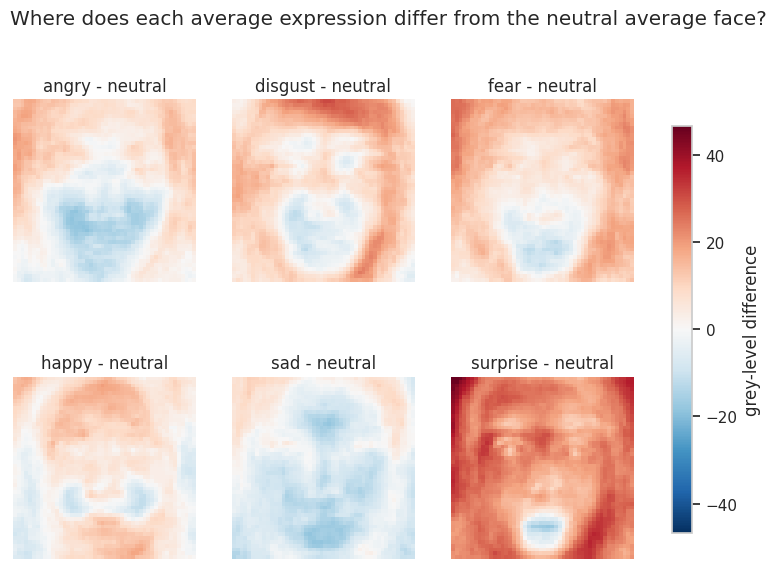

angry     mean diff =    2.0   upper-half mean =    7.5   lower-half mean =   -3.5
disgust   mean diff =    8.4   upper-half mean =   11.3   lower-half mean =    5.4
fear      mean diff =    9.4   upper-half mean =   12.8   lower-half mean =    5.9
happy     mean diff =    4.7   upper-half mean =    7.3   lower-half mean =    2.1
sad       mean diff =   -4.6   upper-half mean =   -1.1   lower-half mean =   -8.0
surprise  mean diff =   21.5   upper-half mean =   23.5   lower-half mean =   19.5


In [36]:
# Chart - 22 visualization code
others = [e for e in EMOTIONS if e != 'neutral']
diffs = {e: mean_faces[e] - mean_faces['neutral'] for e in others}
vmax = max(np.abs(d).max() for d in diffs.values())
fig, axes = plt.subplots(2, 3, figsize=(10, 6.6))
for ax, emo in zip(axes.ravel(), others):
    im = ax.imshow(diffs[emo], cmap='RdBu_r', vmin=-vmax, vmax=vmax)
    ax.set_title(f'{emo} - neutral'); ax.axis('off')
fig.colorbar(im, ax=axes, shrink=0.8, label='grey-level difference')
fig.suptitle('Where does each average expression differ from the neutral average face?')
plt.show()
for emo in others:
    d = diffs[emo]
    print(f'{emo:9s} mean diff = {d.mean():6.1f}   upper-half mean = {d[:24].mean():6.1f}   lower-half mean = {d[24:].mean():6.1f}')

##### 1. Why did you pick the specific chart?

Subtracting the neutral average face turns a visual comparison into a map of **where** each expression changes the picture, combining spatial (x, y) and class information, which is why it is a multivariate view.

##### 2. What is/are the insight(s) found from the chart?

* **Surprise shows a strong, face-wide brightening (mean +21.5 grey levels) with a dark patch at the open mouth**; fear (+9.4) and disgust (+8.4) are moderately brighter, angry (+2.0) and happy (+4.7) are close to neutral, and **sad is darker overall (-4.6)**.
* The most consistent local pattern is a **darker mouth and lower-centre region than neutral for angry, disgust, fear, sad and surprise**. Bright patches near the forehead, hair and borders (notably disgust and surprise) look more like lighting or sampling effects, especially since disgust has only 458 images.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it shows that the mouth and lower-centre region carries consistent expression information, so consistent face alignment is valuable, and class activation maps (Grad-CAM) in the ML notebook can be checked against this expectation to confirm the model looks at sensible regions.

**Negative:** because part of the signal is global brightness (especially for surprise), a model could rely on it instead of facial muscle movement; brightness augmentation and normalisation are needed to force it to learn expression cues.

## **5. Solution to Business Objective**

#### What do you suggest the client to achieve Business Objective ?
Explain Briefly.

**Recommendations for the DeepFER modelling stage, directly derived from this EDA:**

1. **Use the cleaned dataset** (33,975 images) and keep the nested `images/images/` folder out of the pipeline. Removing duplicates and train/validation leakage makes reported accuracy trustworthy.
2. **Re-split carefully:** keep the provided validation set as a final, untouched test set and create a stratified validation set from the training images; consider cross-validation for rare classes such as disgust (only 82 validation images).
3. **Handle class imbalance (19x):** class-weighted cross-entropy and/or oversampling for disgust and surprise, plus augmentation; evaluate with **macro-F1, per-class precision/recall and a confusion matrix**, not accuracy alone.
4. **Augment with label-preserving transforms:** horizontal flip (faces are naturally asymmetric), small rotations (about +/-15 degrees), mild brightness/contrast jitter and slight zoom. Avoid heavy cropping or random erasing that could remove the eye/brow/mouth region.
5. **Normalise inputs:** scale pixels to [0, 1] and standardise; contrast stretching is unnecessary. For pretrained backbones, replicate the grayscale channel to 3 channels and resize (for example to 96-224 px).
6. **Use a CNN / transfer learning model** (global statistics and PCA cannot separate the classes), with regularisation (dropout, batch norm, weight decay), early stopping and learning-rate scheduling.
7. **Guard against shortcuts and label noise:** monitor errors on dark and bright subsets, inspect misclassified images, and use Grad-CAM to confirm the model looks at the central face.
8. **Set expectations for deployment:** accuracy will be limited by ambiguous labels and low resolution (fear vs surprise and sad vs neutral are the likely confusions), and an external test set is recommended before real-world use.

# **Conclusion**

This EDA audited a 48x48 grayscale facial-emotion dataset of 35,887 unique images (the 71,774 files in the archive include an exact duplicate copy). It found no missing values or corrupt files, but it did find **1,853 redundant copies, 510 images leaking from train into validation and 57 groups with conflicting labels**; after cleaning, **33,975 images** remain. Duplication was concentrated in surprise (33%) and disgust (28%), and the resulting class imbalance is severe (happy is 19x larger than disgust).

Across 22 charts, simple image statistics proved to be **weak and heavily overlapping predictors** of emotion: brightness is the strongest (4.4% of variance explained), while contrast, edge density, sharpness, asymmetry and vertical brightness each explain about 1.6% or less. PCA and pair plots confirm that lighting, not expression, dominates pixel variance and that the classes are not separable by global features. The train and validation splits are well matched, the images already use the full dynamic range, and samples show real-world challenges (pose, occlusion, watermarks, ambiguous labels).

The conclusion is a clear modelling strategy: **clean, de-duplicated data; a stratified re-split; class-imbalance handling; label-preserving augmentation including brightness jitter; and a CNN with transfer learning evaluated with macro-F1 and per-class metrics**. Following this plan should give DeepFER a model whose performance estimates are honest and which serves its business goals in human-computer interaction, mental-health monitoring and customer service.

### ***Hurrah! You have successfully completed your EDA Capstone Project !!!***